# 08 — Day-ahead demand forecasting (L0–L6)

**Does:** forecasts every state's peak demand for tomorrow with a ladder of models, each adding one thing, and tests them month by month over 2024 – Mar 2025 the way they would be used: refit at the start of each month on everything before it.

**Question:** how much better than "same as yesterday" can we forecast demand, which features help, and where do forecasts still fail?

**Input:** `data/processed/india_electricity_data_updated.csv`, `data/processed/weather_state_daily.csv` (notebook 06), `data/raw/holidays.csv`, `data/raw/paddy_dates.csv`

**Output:** `data/processed/demand_forecast_test.csv` (every model's forecast for every state and test day; input for Stage 5)

**Code:** `src/features.py` (tested in `tests/test_features.py`: no feature can see the future), `src/forecast.py` (models, walk-forward)

**Logged in:** `docs/model_log.md`, Step 16

## Design (Stage 3 decisions)

| Choice | Value |
|---|---|
| Level | 32 states, **national = sum of states**; plus a direct national model as a yardstick |
| Target | **y = log(demand_T / demand_D)**, the change from today. Forecast = today × exp(y). y = 0 is persistence, so models learn *corrections*: Sunday dip, heat building, holidays. (The log keeps +10% and −10% symmetric; it is the change ratio of decision 2.) |
| Temperature | Cooling degree days above 24 °C, heating degree days below 18 °C (daily mean); change from today to tomorrow |
| Calendar | Weekday and month of tomorrow; holidays tomorrow and today (national + regional, `holidays.csv`); paddy season flag for Punjab and Haryana (`paddy_dates.csv`) |
| COVID | Target days 25 Mar – 1 Jun 2020 (lockdown) not used for fitting |
| Weather for tomorrow | **perfect** = tomorrow's actual weather (upper bound); **persistence** = today's weather (lower bound) |
| Test | Walk-forward: 15 monthly refits, Jan 2024 – Mar 2025 |
| Score | National MAE / MAPE / RMSE of the summed forecast; skill = 1 − MAE / MAE(persistence); target **skill ≥ 0.20** |

| Step | Model | Adds |
|---|---|---|
| L0 | Persistence; last week | baselines |
| L1 | Average change by state × weekday × month | the regular weekly/seasonal pattern |
| L2 | Ridge regression | recent changes, holidays, paddy |
| L3 | L2 + weather | degree days, rain |
| L4 | LightGBM | non-linear effects, raw temperatures |
| L5 | One model per state (L3, L4) | vs one pooled model |
| L6 | LightGBM quantiles (10%, 50%, 90%) | an 80% range |

In [1]:
import sys
sys.path.append("../src")

import time, itertools
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import features as F
import forecast as fc
from dispatch import load_demand, PROCESSED

demand = load_demand()
state_weather = pd.read_csv(PROCESSED / "weather_state_daily.csv", parse_dates=["Date"])
holidays, paddy = F.load_holidays(), F.load_paddy()
feats = {w: F.build_features(demand, state_weather, holidays, paddy, w) for w in F.WEATHER_CASES}
f = feats["perfect"]
print(f.shape, f.Date.min().date(), "→", f.Date.max().date())
assert all(not x.isna().any().any() for x in feats.values())

(61088, 27) 2020-01-09 → 2025-03-31


## 1. What the target looks like

Punjab around the 2024 paddy start (11 June): demand jumps ~10% a day for two days as pumps switch on. `d_paddy` = 1 on the first paddy day.

In [2]:
f.query("State == 'Punjab' and '2024-06-08' <= Date <= '2024-06-14'")[
    ["Date", "Base", "Actual", "y", "paddy_T", "d_paddy", "r_lastweek", "d_cdd"]].round(3)

/var/folders/88/lq1yf9zd00v9hqd9g1xtfl000000gn/T/ipykernel_14453/2687782193.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ["Date", "Base", "Actual", "y", "paddy_T", "d_paddy", "r_lastweek", "d_cdd"]].round(3)


,Date,Base,Actual,y,paddy_T,d_paddy,r_lastweek,d_cdd
51606,2024-06-08,11780.0,11664.0,-0.010,0,0.0,-0.153,-0.77
51638,2024-06-09,11664.0,11316.0,-0.030,0,0.0,0.006,1.24
51670,2024-06-10,11316.0,12564.0,0.105,0,0.0,0.104,0.20
51702,2024-06-11,12564.0,13870.0,0.099,1,1.0,-0.039,0.99
51734,2024-06-12,13870.0,14731.0,0.060,1,0.0,0.091,1.31
51766,2024-06-13,14731.0,15438.0,0.047,1,0.0,-0.258,0.19
51798,2024-06-14,15438.0,15815.0,0.024,1,0.0,0.051,-0.19


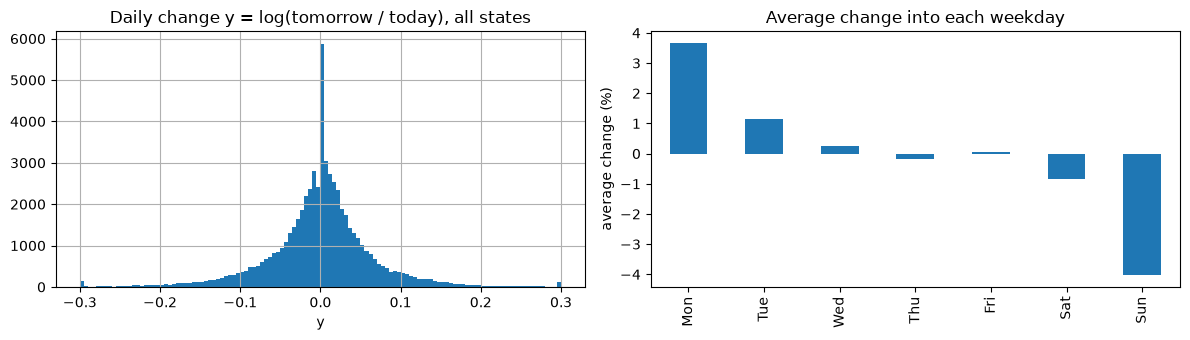

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
f["y"].clip(-0.3, 0.3).hist(bins=120, ax=axes[0])
axes[0].set_title("Daily change y = log(tomorrow / today), all states"); axes[0].set_xlabel("y")
by_day = f.groupby("weekday_T")["y"].mean() * 100
by_day.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day.plot.bar(ax=axes[1]); axes[1].set_ylabel("average change (%)")
axes[1].set_title("Average change into each weekday")
plt.tight_layout(); plt.show()

## 2. Tuning LightGBM — on 2023 only

Train on 2020–22, score on 2023, pick the settings; the test period (2024–25) is never used for choices.

In [4]:
train = fc.training_rows(f[f.Date < "2023-01-01"])
val = f[f.Date.between("2023-01-01", "2023-12-31")]
grid = []
for nl, lr, ne, mcs in itertools.product([15, 31, 63], [0.03, 0.1], [300, 800], [20, 100]):
    m = fc.Trees(fc.FEATURE_SETS["L4"], dict(num_leaves=nl, learning_rate=lr, n_estimators=ne,
                                              min_child_samples=mcs)).fit(train)
    g = val.assign(F=val.Base * np.exp(m.predict(val))).groupby("Date")[["Actual", "F"]].sum()
    grid.append(dict(num_leaves=nl, learning_rate=lr, n_estimators=ne, min_child_samples=mcs,
                     national_MAE=(g.Actual - g.F).abs().mean()))
grid = pd.DataFrame(grid).sort_values("national_MAE")
best = grid.iloc[0]
assert all(fc.LGBM_PARAMS[k] == best[k] for k in ["num_leaves", "learning_rate", "n_estimators", "min_child_samples"])
print(f"MAE range over the grid: {grid.national_MAE.min():,.0f} – {grid.national_MAE.max():,.0f} MW")
grid.head(5).round(0)

MAE range over the grid: 2,411 – 2,598 MW


,num_leaves,learning_rate,n_estimators,min_child_samples,national_MAE
11,31,0.0,800,100,2411.0
6,15,0.0,800,20,2422.0
4,15,0.0,300,20,2431.0
19,63,0.0,800,100,2432.0
17,63,0.0,300,100,2435.0


Settings matter little (all 24 within ~8%). The best set is stored as `LGBM_PARAMS` in `src/forecast.py` (the assert checks it).

## 3. The ladder, walk-forward over Jan 2024 – Mar 2025

In [5]:
L = fc.FEATURE_SETS
ladder = {
    "L0 persistence": fc.Persistence,
    "L0 last week": fc.LastWeek,
    "L1 profile": fc.Profile,
    "L2 linear": lambda: fc.Linear(L["L2"]),
    "L3 linear + weather": lambda: fc.Linear(L["L3"]),
    "L4 LightGBM": lambda: fc.Trees(L["L4"]),
    "L5 linear per state": lambda: fc.PerState(lambda: fc.Linear(L["L3"])),
    "L5 LightGBM per state": lambda: fc.PerState(lambda: fc.Trees(L["L4"])),
    "L6 LightGBM median": lambda: fc.Trees(L["L4"], quantile=0.5),
}
NO_WEATHER = ["L0 persistence", "L0 last week", "L1 profile", "L2 linear"]

preds = []
for name, make in ladder.items():
    for weather in (["none"] if name in NO_WEATHER else list(F.WEATHER_CASES)):
        t = time.time()
        p = fc.walk_forward(feats["perfect" if weather == "none" else weather], make)
        preds.append(p[["State", "Date", "Base", "Actual", "Forecast"]].assign(Model=name, Weather=weather))
        print(f"{name:24s} {weather:12s} {time.time() - t:6.1f} s")
preds = pd.concat(preds, ignore_index=True)

L0 persistence           none            0.1 s
L0 last week             none            0.1 s


L1 profile               none            0.2 s


L2 linear                none            0.7 s


L3 linear + weather      perfect         0.6 s


L3 linear + weather      persistence     0.5 s


...

L5 linear per state      persistence     2.2 s


L5 LightGBM per state    perfect       504.8 s


L5 LightGBM per state    persistence   489.8 s


L6 LightGBM median       perfect        69.0 s


L6 LightGBM median       persistence    66.9 s


In [6]:
def national_scores(p, base_mae):
    g = p.groupby("Date")[["Actual", "Forecast"]].sum()
    return fc.score(g.Actual, g.Forecast, base_mae)

base_mae = national_scores(preds[preds.Model == "L0 persistence"], None)["MAE"]
rows = []
for (model, weather), p in preds.groupby(["Model", "Weather"], sort=False):
    s = national_scores(p, base_mae)
    s["state MAPE_%"] = ((p.Actual - p.Forecast).abs() / p.Actual).mean() * 100
    rows.append({"Model": model, "Weather": weather, **s})
results = pd.DataFrame(rows).set_index(["Model", "Weather"])
results.round({"MAE": 0, "MAPE_%": 2, "RMSE": 0, "Skill": 3, "state MAPE_%": 2})

MAE  MAPE_%    RMSE  Skill  state MAPE_%
Model                 Weather                                                 
L0 persistence        none         4842.0    2.22  6501.0  0.000          4.71
L0 last week          none         6841.0    3.14  9178.0 -0.413          6.86
L1 profile            none         3344.0    1.54  4718.0  0.310          4.12
L2 linear             none         3101.0    1.42  4333.0  0.360          4.06
L3 linear + weather   perfect      2834.0    1.30  3987.0  0.415          3.94
                      persistence  3062.0    1.40  4272.0  0.368          4.03
L4 LightGBM           perfect      2542.0    1.17  3586.0  0.475          3.43
                      persistence  2793.0    1.28  3894.0  0.423          3.61
L5 linear per state   perfect      2726.0    1.25  3906.0  0.437          3.57
                      persistence  2980.0    1.36  4163.0  0.384          3.71
L5 LightGBM per state perfect      2508.0    1.16  3845.0  0.482          3.64
                      persistence  2790.0    1.28  4094.0  0.424          3.78
L6 LightGBM median    perfect      2416.0    1.11  3618.0  0.501          3.40
                      persistence  2711.0    1.25  4013.0  0.440          3.57

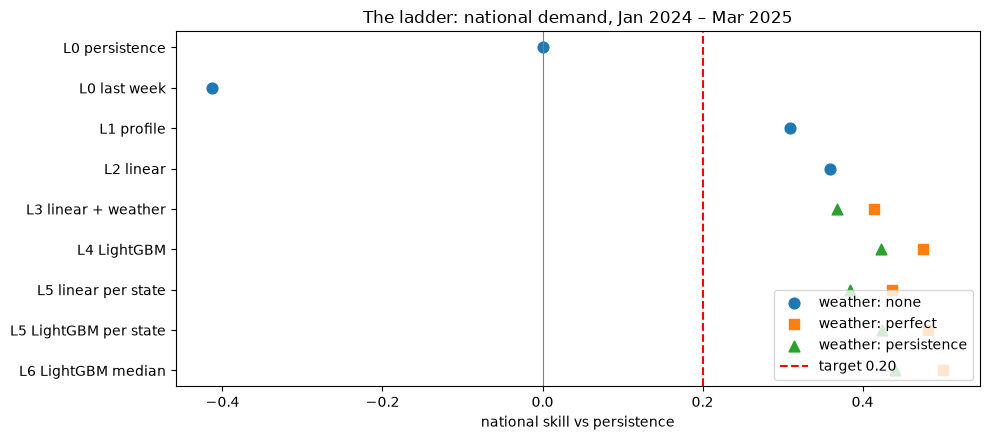

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
r = results.reset_index()
for weather, marker in [("none", "o"), ("perfect", "s"), ("persistence", "^")]:
    q = r[r.Weather == weather]
    ax.scatter(q.Skill, q.Model, marker=marker, s=60, label=f"weather: {weather}")
ax.axvline(0.20, color="red", ls="--", label="target 0.20"); ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("national skill vs persistence"); ax.invert_yaxis(); ax.legend(loc="lower right")
ax.set_title("The ladder: national demand, Jan 2024 – Mar 2025")
plt.tight_layout(); plt.show()

### Direct national model (yardstick)

Same models fitted to the national total directly. If summing state forecasts lost accuracy, the direct model would win.

In [8]:
nat_f = {w: fc.national_features(feats[w], demand) for w in F.WEATHER_CASES}
direct = []
for name in ["L3 linear + weather", "L4 LightGBM"]:
    for weather in F.WEATHER_CASES:
        p = fc.walk_forward(nat_f[weather], ladder[name])
        s = fc.score(p.Actual, p.Forecast, base_mae)
        bottom_up = results.loc[(name, weather)]
        direct.append({"Model": name, "Weather": weather, "direct MAE": s["MAE"], "bottom-up MAE": bottom_up["MAE"]})
        preds = pd.concat([preds, p[["State", "Date", "Base", "Actual", "Forecast"]].assign(
            Model=name + " (direct national)", Weather=weather)], ignore_index=True)
pd.DataFrame(direct).round(0)

,Model,Weather,direct MAE,bottom-up MAE
0,L3 linear + weather,perfect,2840.0,2834.0
1,L3 linear + weather,persistence,2982.0,3062.0
2,L4 LightGBM,perfect,2646.0,2542.0
3,L4 LightGBM,persistence,2981.0,2793.0


## 4. What the models learned

In [9]:
lin = fc.Linear(L["L3"]).fit(fc.training_rows(f[f.Date < fc.TEST_START]))
coef = pd.Series(lin.model.coef_ / lin.std.to_numpy(), index=lin.columns)   # per unit of each feature

carry = coef[fc.RECENT].rename({
    "r_D_vs_Dm1": "today's change vs yesterday", "r_D_vs_Dm7": "today vs a week ago",
    "r_lastweek": "last week's change into the same weekday"})
effects = ((np.exp(coef[fc.CALENDAR + fc.WEATHER]) - 1) * 100).rename({
    "d_cdd": "+1 cooling degree day (vs today)", "d_hdd": "+1 heating degree day (vs today)",
    "rain_T": "+1 mm rain tomorrow", "rain_3d": "+1 mm rain in the last 3 days", "d_tmax": "+1 °C max temperature",
    "hol_T": "tomorrow is a holiday", "hol_D": "today is a holiday", "d_hol": "(holiday change)",
    "paddy_T": "in paddy season", "d_paddy": "first paddy day"})
display(carry.round(3).rename("share carried into tomorrow's change").to_frame())
effects.round(2).rename("effect on tomorrow's demand (%)").to_frame()

,share carried into tomorrow's change
today's change vs yesterday,-0.158
today vs a week ago,-0.140
last week's change into the same weekday,0.231


,effect on tomorrow's demand (%)
tomorrow is a holiday,-2.20
today is a holiday,-1.05
(holiday change),-0.58
in paddy season,-0.20
first paddy day,3.76
+1 cooling degree day (vs today),1.58
+1 heating degree day (vs today),0.19
+1 mm rain tomorrow,-0.07
+1 mm rain in the last 3 days,0.00
+1 °C max temperature,0.18


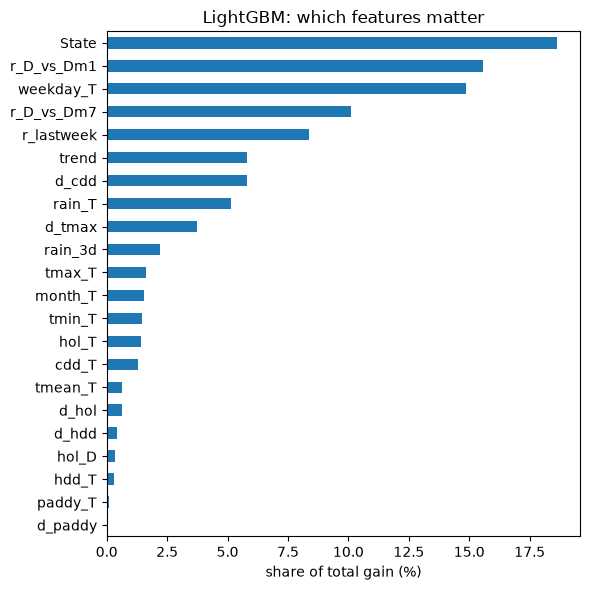

In [10]:
trees = fc.Trees(L["L4"]).fit(fc.training_rows(f[f.Date < fc.TEST_START]))
imp = pd.Series(trees.model.booster_.feature_importance("gain"), index=trees.model.booster_.feature_name())
(imp / imp.sum() * 100).sort_values().plot.barh(figsize=(6, 6))
plt.xlabel("share of total gain (%)"); plt.title("LightGBM: which features matter"); plt.tight_layout(); plt.show()

## 5. Ranges (L6): how often does the actual fall inside the 80% range?

In [11]:
q = {}
for alpha in (0.1, 0.9):
    p = fc.walk_forward(feats["perfect"], lambda: fc.Trees(L["L4"], quantile=alpha))
    q[alpha] = p.set_index(["Date", "State"])["Forecast"]
band = pd.DataFrame({"Q10": q[0.1], "Q90": q[0.9]}).join(
    preds.query("Model == 'L6 LightGBM median' and Weather == 'perfect'").set_index(["Date", "State"])[["Actual"]])
inside = band.Actual.between(band.Q10, band.Q90)
print(f"inside the 10–90% range: {inside.mean():.1%} (should be ~80%)")
print(f"average width: {((band.Q90 - band.Q10) / band.Actual).mean():.1%} of demand")
preds = preds.merge(band[["Q10", "Q90"]].reset_index().assign(Model="L6 LightGBM median", Weather="perfect"),
                    on=["Date", "State", "Model", "Weather"], how="left")
inside.groupby(level="State").mean().sort_values().head(5).round(2).rename("coverage, worst 5 states").to_frame()

inside the 10–90% range: 75.1% (should be ~80%)
average width: 9.4% of demand


,"coverage, worst 5 states"
State,
Manipur,0.67
Haryana,0.72
DD & DNH,0.72
Delhi,0.72
Puducherry,0.73


## 6. Where do forecasts still fail?

Best pooled model (L4 LightGBM, perfect weather) against persistence.

In [12]:
best_name = "L4 LightGBM"
best = preds.query("Model == @best_name and Weather == 'perfect'")
pers = preds.query("Model == 'L0 persistence'")

def nat(p):
    g = p.groupby("Date")[["Actual", "Forecast"]].sum()
    return (g.Actual - g.Forecast).abs()

err = pd.DataFrame({"persistence": nat(pers), best_name: nat(best)}) / 1000
err["weekday"] = err.index.day_name()
nat_hol = holidays[holidays.Scope == "national"].Date
err["situation"] = np.select(
    [err.index.isin(nat_hol), err.index.isin(nat_hol + pd.Timedelta(days=1)),
     (err.index >= "2024-05-17") & (err.index <= "2024-06-19")],
    ["national holiday", "day after a holiday", "heatwave 17 May – 19 Jun 2024"], "other")
summary = pd.concat({
    "by weekday": err.groupby("weekday")[["persistence", best_name]].mean().reindex(
        ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]),
    "by situation": err.groupby("situation")[["persistence", best_name]].mean()})
summary.round(2).rename(columns=lambda c: c + " MAE (GW)")

persistence MAE (GW)  \
by weekday   Monday                                        10.21   
             Tuesday                                        2.72   
             Wednesday                                      2.79   
             Thursday                                       3.39   
             Friday                                         3.22   
             Saturday                                       3.24   
             Sunday                                         8.23   
by situation day after a holiday                            5.98   
             heatwave 17 May – 19 Jun 2024                  4.84   
             national holiday                               8.57   
             other                                          4.58   

                                            L4 LightGBM MAE (GW)  
by weekday   Monday                                         2.94  
             Tuesday                                        2.21  
             Wednesday                                      2.55  
             Thursday                                       2.50  
             Friday                                         3.08  
             Saturday                                       2.27  
             Sunday                                         2.25  
by situation day after a holiday                            3.55  
             heatwave 17 May – 19 Jun 2024                  2.22  
             national holiday                               7.39  
             other                                          2.25

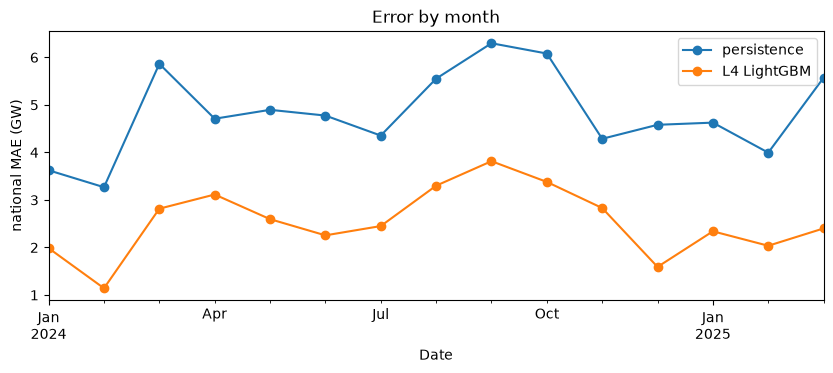

In [13]:
by_month = err.groupby(err.index.to_period("M"))[["persistence", best_name]].mean()
by_month.plot(marker="o", figsize=(10, 3.5)); plt.ylabel("national MAE (GW)")
plt.title("Error by month"); plt.show()

In [14]:
state_err = pd.DataFrame({
    m: p.assign(e=(p.Actual - p.Forecast).abs() / p.Actual).groupby("State").e.mean() * 100
    for m, p in [("persistence", pers), (best_name, best)]})
state_err["skill"] = 1 - (best.assign(e=(best.Actual - best.Forecast).abs()).groupby("State").e.mean()
                          / pers.assign(e=(pers.Actual - pers.Forecast).abs()).groupby("State").e.mean())
state_err.sort_values("skill").round(2).rename(columns={"persistence": "persistence MAPE %",
                                                       best_name: best_name + " MAPE %"})

,persistence MAPE %,L4 LightGBM MAPE %,skill
State,,,
J&K(UT) & Ladakh(UT),2.79,2.64,0.05
ER Odisha,3.69,3.43,0.07
Manipur,6.07,5.58,0.08
Chhattisgarh,2.38,2.10,0.11
Rajasthan,2.74,2.37,0.13
Arunachal Pradesh,5.69,4.95,0.13
MP,2.54,2.14,0.13
NR UP,2.99,2.57,0.14
Andhra Pradesh,2.96,2.53,0.14


In [15]:
worst = err.sort_values(best_name, ascending=False).head(8)
worst.round(2)

,persistence,L4 LightGBM,weekday,situation
Date,,,,
2025-03-14,26.33,19.87,Friday,national holiday
2024-10-31,20.54,15.34,Thursday,national holiday
2025-02-26,2.62,14.57,Wednesday,national holiday
2024-11-01,10.38,13.84,Friday,day after a holiday
2024-08-16,14.05,12.49,Friday,day after a holiday
2024-03-25,14.00,12.23,Monday,national holiday
2024-10-12,16.62,11.54,Saturday,national holiday
2024-03-29,1.95,10.88,Friday,national holiday


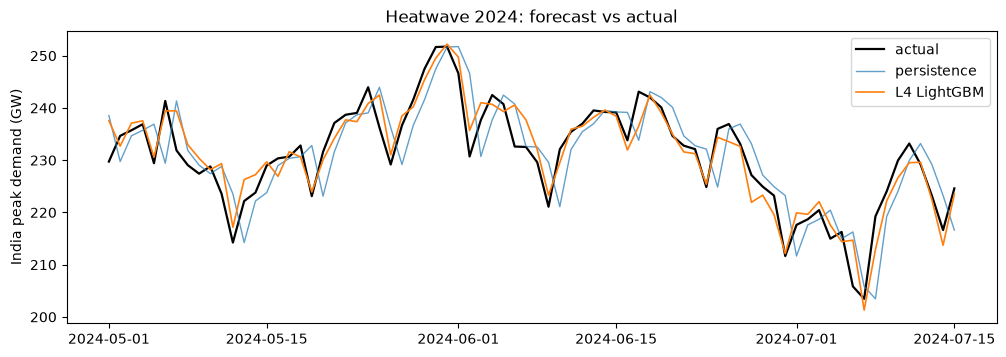

In [16]:
fig, ax = plt.subplots(figsize=(12, 3.8))
window = slice("2024-05-01", "2024-07-15")
g = best.groupby("Date")[["Actual", "Forecast"]].sum().loc[window] / 1000
gp = pers.groupby("Date")["Forecast"].sum().loc[window] / 1000
ax.plot(g.Actual, color="black", lw=1.6, label="actual")
ax.plot(gp, lw=1, alpha=0.7, label="persistence")
ax.plot(g.Forecast, lw=1.2, label=best_name)
ax.set_ylabel("India peak demand (GW)"); ax.legend(); ax.set_title("Heatwave 2024: forecast vs actual")
plt.show()

## 7. Save

In [17]:
out = preds[["Date", "State", "Model", "Weather", "Forecast", "Q10", "Q90", "Actual"]]
out.to_csv(PROCESSED / "demand_forecast_test.csv", index=False, float_format="%.1f")
print(f"saved {len(out):,} rows: {out.Model.nunique()} models, {out.State.nunique()} areas")

saved 206,112 rows: 11 models, 33 areas


## Conclusions

**The target (skill ≥ 0.20) is met by every model from L1 up.** National MAE over Jan 2024 – Mar 2025, perfect weather:

| Step | National MAE | Skill | What it added |
|---|---|---|---|
| L0 persistence | 4,842 MW | 0 | — |
| L1 profile | 3,344 MW | 0.31 | the weekly pattern alone removes most of the Monday/Sunday error |
| L2 linear | 3,101 MW | 0.36 | recent changes, holidays, paddy |
| L3 + weather | 2,834 MW | 0.42 | degree days and rain |
| L4 LightGBM | 2,542 MW | 0.48 | non-linear effects |
| **L6 LightGBM median** | **2,416 MW (1.11%)** | **0.50** | fitting the median (absolute error) instead of the mean: less pulled by unusual days |

- **Weather is worth ~10%:** L4 with today's weather standing in for tomorrow's: 2,793 MW (skill 0.42) vs 2,542 with perfect weather. A real weather forecast would land in between
- **Pooled vs per state (L5):** per-state *linear* models beat the pooled one (2,726 vs 2,834: each state has its own weekly rhythm). Per-state LightGBM is about equal nationally (2,508) but **worse for states** (MAPE 3.64% vs 3.43%) and 8× slower, so the pooled LightGBM is preferred
- **Bottom-up is fine:** summing 32 state forecasts is as good as or better than forecasting India directly (L4: 2,542 vs 2,646 MW)
- **Ranges (L6):** 75% of actual values fall inside the 10–90% range (should be 80%); average width 9.4% of demand. Slightly overconfident

**What the models learned (L3 coefficients):** 23% of last week's change into the same weekday repeats; 16% of today's jump reverses tomorrow; a holiday tomorrow −2.2%; the first paddy day +3.8%; each extra cooling degree day +1.6%; rain −0.07% per mm.

**Where forecasts still fail:**
- **Fixed:** Mondays (persistence 10.2 → 2.9 GW), Sundays (8.2 → 2.3 GW), and the **May–June 2024 heatwave (4.8 → 2.2 GW)**
- **Still weak: holidays.** National holidays average 7.4 GW error vs 2.3 GW on normal days. The largest misses are Holi 2025 (19.9 GW) and Diwali 2024 (15.3 GW), where demand fell more than the model expected, and **Maha Shivratri 2025 (14.6 GW) and Good Friday 2024 (10.9 GW), where the model predicted a dip that didn't happen** (persistence was off by only 2–3 GW). All national holidays are treated alike, but big festivals cut demand much more than minor ones. A holiday-type feature (major / minor) is the obvious next improvement
- **By state:** every state improves on persistence. Most: Tamil Nadu (skill 0.52), Goa, Sikkim, Mizoram. Least: J&K (0.05), Odisha (0.07), Manipur (0.08): little weekly pattern, and outages that no feature can see

**For Stage 5 (demand → dispatch → price):** L6 LightGBM median (pooled) as the main forecast, L4 as the alternative, both weather cases. Saved in `demand_forecast_test.csv`.